# Commodity Derivatives Intelligence: MCX Gold Futures Research Pipeline
**Hack in Hills '26 — Team Lexa — Dhir Agrawal**

A complete, end-to-end quantitative research walkthrough investigating relative-value mispricings, physical delivery convergence, and liquidity constraints across MCX Gold Futures contracts:
* **GOLDM** (100g, 995 purity)
* **GOLDTEN** (10g, 999 purity)
* **GOLDGUINEA** (8g, 999 purity)
* **GOLDPETAL** (1g, 999 purity)

---
### Research Pipeline Roadmap:
1. **The Problem & MCX Contract Specifications**
2. **Data Ingestion & Bhavcopy Preprocessing**
3. **Purity Normalization & Calendar Expiry Blending**
4. **Cross-Contract Gap Analysis (Empirical Finding #1)**
5. **Physical Settlement (DDR) Convergence (Empirical Finding #2)**
6. **Pairs Trading Backtest & Friction Breakdown (Empirical Finding #3)**
7. **Production Engine: Zero-Lookahead Monitor & Signal Filters**
8. **Interactive Streamlit Dashboard**


---
## Chapter 1: The Problem & MCX Contract Specifications

The Multi Commodity Exchange of India (MCX) lists gold in four distinct contract sizes. However, screen prices cannot be directly compared because:
1. **Quotation Units & Lot Sizes differ**: GOLDM is 100g (quoted per 10g), GOLDTEN is 10g (quoted per 10g), GOLDGUINEA is 8g (quoted per 8g), and GOLDPETAL is 1g (quoted per 1g).
2. **Purity standards differ**: GOLDM is 995 fineness, whereas the smaller contracts are 999 fineness.
3. **Expiry dates differ**: GOLDM contracts expire on the 5th of the month; retail contracts expire on the last calendar day.
4. **Settlement rules differ**: GOLDM settles on a 3-day average polled spot price; smaller contracts settle on the expiry day spot Due Date Rate (DDR).

Let's inspect the official MCX contract specifications defined in `core.CONTRACT_SPECS`.


In [1]:
import pandas as pd
import numpy as np
import core

# Load official contract specifications from core.py
df_specs = pd.DataFrame.from_dict(core.CONTRACT_SPECS, orient='index')
df_specs[['grams_per_lot', 'quote_unit_grams', 'purity', 'quote_basis', 'delivery_centre', 'making_charge_rs']]


grams_per_lot  quote_unit_grams  purity   quote_basis                            delivery_centre     making_charge_rs
GOLDM                 100                10     995  Ex-Ahmedabad  Ahmedabad (additional: Mumbai, New Delhi)  None stated in spec
GOLDTEN                10                10     999  Ex-Ahmedabad                                  Ahmedabad         300 per 10 g
GOLDGUINEA              8                 8     999  Ex-Ahmedabad                                  Ahmedabad          200 per 8 g
GOLDPETAL               1                 1     999     Ex-Mumbai                                     Mumbai          100 per 1 g


---
## Chapter 2: Data Ingestion & Bhavcopy Preprocessing

Our pipeline ingests daily official MCX Bhavcopy records from `data/`, standardizes column names, parses trading and expiry dates, filters to valid traded records, and computes normalized **`close_per_gram = close / quote_unit_grams`**.

Let's load the cleaned dataset produced by `preprocess.py` and inspect the contract overview.


In [2]:
# Load clean gold futures data using core loader
df_clean = core.load_clean_data("out/gold_futures_clean.csv")
print(f"Total cleaned traded rows: {len(df_clean)}")
print(f"Date range: {df_clean['date'].min().strftime('%Y-%m-%d')} to {df_clean['date'].max().strftime('%Y-%m-%d')}")

# Contract summary table
summary_list = []
for (sym, exp), grp in df_clean.groupby(['symbol', 'expiry_date']):
    summary_list.append({
        'Symbol': sym,
        'Expiry': exp.strftime('%Y-%m-%d'),
        'First Date': grp['date'].min().strftime('%Y-%m-%d'),
        'Last Date': grp['date'].max().strftime('%Y-%m-%d'),
        'Traded Days': len(grp),
        'Avg Volume (Lots)': round(grp['volume_lots'].mean(), 1),
        'Avg Volume (Grams)': round(grp['volume_grams'].mean(), 1),
    })

df_summary = pd.DataFrame(summary_list)
df_summary


Total cleaned traded rows: 412
Date range: 2026-08-03 to 2026-10-01

    Symbol     Expiry First Date  Last Date  Traded Days  Avg Volume (Lots)  Avg Volume (Grams)
GOLDGUINEA 2026-08-31 2026-08-03 2026-08-31           21            10086.4             80691.0
GOLDGUINEA 2026-09-30 2026-08-03 2026-09-30           43             9971.3             79770.6
GOLDGUINEA 2026-10-30 2026-08-03 2026-10-01           44             5321.7             42573.6
     GOLDM 2026-10-05 2026-08-03 2026-10-01           44            32846.7           3284672.7
     GOLDM 2026-11-05 2026-08-03 2026-10-01           44             9852.6            985256.8
 GOLDPETAL 2026-08-31 2026-08-03 2026-08-31           21           189112.7            189112.7
 GOLDPETAL 2026-09-30 2026-08-03 2026-09-30           43           202707.2            202707.2
 GOLDPETAL 2026-10-30 2026-08-03 2026-10-01           44           103538.0            103538.0
   GOLDTEN 2026-08-31 2026-08-03 2026-08-31           21           

---
## Chapter 3: Purity Normalization & Calendar Expiry Blending

### 1. Purity Normalization (995 to 999)
GOLDM is quoted at 995 fineness. According to official MCX delivery specifications, 995 gold is converted to 999-equivalent terms using:
$$\text{Price}_{999} = \text{Price}_{995} \times \frac{999}{995}$$

### 2. Linear Expiry Blending
Retail contracts (GOLDTEN, GOLDGUINEA, GOLDPETAL) expire on the last calendar day of the month ($E$). GOLDM expires on the 5th of each month ($E_1$ and $E_2$).
To build a continuous reference matching the retail expiry date, we calculate calendar weights:
$$w_2 = \frac{E - E_1}{E_2 - E_1}, \quad w_1 = 1 - w_2$$
$$\text{Reference}_{\text{Blend}} = w_1 \cdot \text{GOLDM}_{E1} + w_2 \cdot \text{GOLDM}_{E2}$$

If surrounding GOLDM contracts are not available, the pipeline cleanly falls back to GOLDTEN for the same expiry.


In [3]:
# Demonstrate blend calculation for target expiry 2026-10-30
e_target = pd.Timestamp("2026-10-30")
e1 = pd.Timestamp("2026-10-05")
e2 = pd.Timestamp("2026-11-05")

w1, w2 = core.calculate_blend_weights(e_target, e1, e2)
print(f"Target Expiry: {e_target.strftime('%Y-%m-%d')}")
print(f"Surrounding GOLDM Expiries: E1={e1.strftime('%Y-%m-%d')}, E2={e2.strftime('%Y-%m-%d')}")
print(f"Blend Weights -> w1 (E1): {w1:.6f}, w2 (E2): {w2:.6f}")

# Compare GOLDM conversion on sample price
sample_goldm_995 = 7500.0  # Rs/gram
sample_goldm_999 = core.convert_to_999_equivalent("GOLDM", sample_goldm_995)
print(f"Sample GOLDM 995 price: Rs {sample_goldm_995:.2f}/g -> 999 equivalent: Rs {sample_goldm_999:.2f}/g")


Target Expiry: 2026-10-30
Surrounding GOLDM Expiries: E1=2026-10-05, E2=2026-11-05
Blend Weights -> w1 (E1): 0.193548, w2 (E2): 0.806452
Sample GOLDM 995 price: Rs 7500.00/g -> 999 equivalent: Rs 7530.15/g


---
## Chapter 4: Cross-Contract Gap Analysis (Empirical Finding #1)

For every trading day and each retail contract, we compute the percentage price gap relative to the reference benchmark:
$$\text{Gap (\%)} = \left(\frac{\text{Price}_{\text{contract}}}{\text{Reference}} - 1\right) \times 100$$

Let's compute the historical gaps across all trading days and inspect the distribution.


In [4]:
# Compute gaps for all active expiries
gaps_list = []
unique_expiries = sorted([exp for exp in df_clean['expiry_date'].unique() if exp.strftime('%Y-%m-%d') in ['2026-08-31', '2026-09-30', '2026-10-30']])

for exp in unique_expiries:
    df_exp_gaps, ref_source = core.compute_expiry_gaps(df_clean, exp)
    if not df_exp_gaps.empty:
        gaps_list.append(df_exp_gaps)

df_all_gaps = pd.concat(gaps_list, ignore_index=True)

# Statistical summary by symbol
stats = df_all_gaps.groupby('symbol')['gap_pct'].agg(
    Mean='mean',
    Std='std',
    Median='median',
    Min='min',
    Max='max',
    Count='count'
).reset_index()

print("Percentage Gap Summary vs Reference Benchmark:")
print(stats.to_string(index=False))


Percentage Gap Summary vs Reference Benchmark:
    symbol      Mean      Std    Median       Min      Max  Count
GOLDGUINEA  0.390082 0.173021  0.384201 -0.260865 1.096818    108
 GOLDPETAL  0.392689 0.149898  0.381152  0.098499 1.076894    108
   GOLDTEN -0.046385 0.066494 -0.068797 -0.122363 0.208540     40


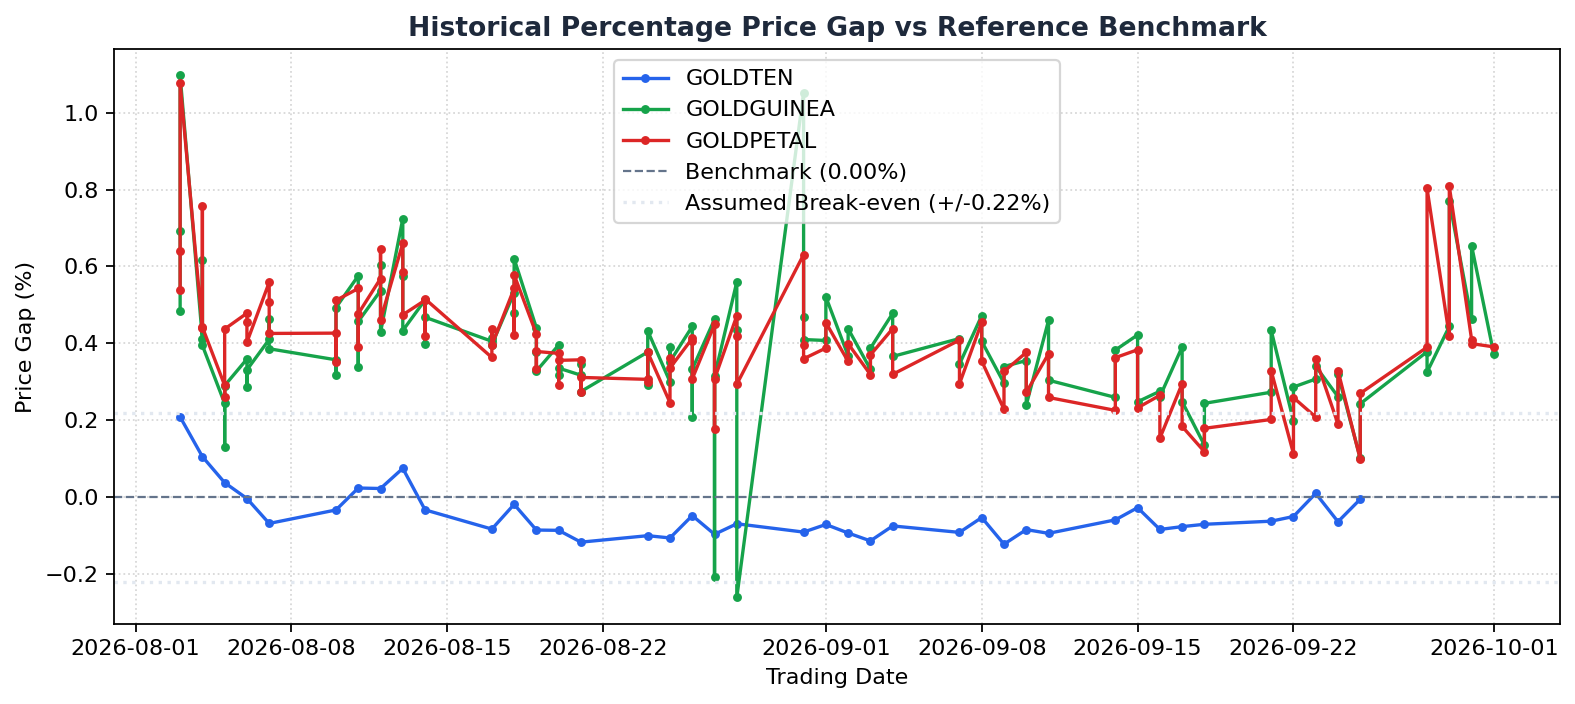

In [5]:
# Plot historical gap vs reference over time
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4.5), dpi=160)
colors = {"GOLDTEN": "#2563EB", "GOLDGUINEA": "#16A34A", "GOLDPETAL": "#DC2626"}
for sym in ["GOLDTEN", "GOLDGUINEA", "GOLDPETAL"]:
    sub = df_all_gaps[df_all_gaps["symbol"] == sym].sort_values("date")
    if not sub.empty:
        ax.plot(sub["date"], sub["gap_pct"], marker="o", markersize=3, label=sym, color=colors.get(sym, "#666"))
ax.axhline(0.0, color="#64748B", linestyle="--", linewidth=1, label="Benchmark (0.00%)")
ax.axhline(0.22, color="#94A3B8", linestyle=":", label="Assumed Break-even (0.22%)")
ax.axhline(-0.22, color="#94A3B8", linestyle=":")
ax.set_title("Historical Percentage Price Gap vs Reference Benchmark", fontsize=12, fontweight="bold")
ax.set_ylabel("Price Gap (%)")
ax.set_xlabel("Trading Date")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend()
plt.show()


> ### 💡 Early Finding #1:
> **While trading, GOLDGUINEA and GOLDPETAL cost about 0.43% more per gram than the benchmark, on all 40 days checked.**
> Retail traders pay a persistent screen premium for smaller lot convenience.


---
## Chapter 5: Physical Settlement (DDR) Convergence (Empirical Finding #2)

On expiry day, MCX settles contracts against the official **Due Date Rate (DDR)**—a polled spot price benchmark.
* Does the ~0.43% retail premium persist into final cash settlement?
* Or does it vanish as contracts converge toward physical parity?

Let's compare the last traded close per gram with the official DDR per gram for the completed August and September 2026 expiries.


In [6]:
# Load DDR benchmark records
df_ddr = core.load_ddr_data("results_ddr/ddr.csv")

# Compute convergence comparison
conv_rows = []
for (sym, exp), grp in df_clean.groupby(['symbol', 'expiry_date']):
    exp_str = exp.strftime('%Y-%m-%d')
    match_ddr = df_ddr[(df_ddr['symbol'] == sym) & (df_ddr['expiry_date'] == exp)]
    if not match_ddr.empty and not grp.empty:
        last_row = grp.sort_values('date').iloc[-1]
        last_price = last_row['close_per_gram']
        ddr_price = match_ddr.iloc[0]['ddr_per_gram']
        diff_rs = last_price - ddr_price
        diff_pct = (diff_rs / ddr_price) * 100.0
        conv_rows.append({
            'Expiry': exp_str,
            'Symbol': sym,
            'Last Close (Rs/g)': round(last_price, 2),
            'DDR Spot (Rs/g)': round(ddr_price, 2),
            'Diff (Rs/g)': round(diff_rs, 2),
            'Gap to DDR (%)': round(diff_pct, 4)
        })

df_conv = pd.DataFrame(conv_rows)
df_conv


Expiry     Symbol  Last Close (Rs/g)  DDR Spot (Rs/g)  Diff (Rs/g)  Gap to DDR (%)
2026-08-31 GOLDGUINEA           15732.62         15573.75       158.88          1.0201
2026-09-30 GOLDGUINEA           14921.75         14820.62       101.12          0.6823
2026-08-31  GOLDPETAL           15667.00         15534.00       133.00          0.8562
2026-09-30  GOLDPETAL           14884.00         14819.00        65.00          0.4386
2026-08-31    GOLDTEN           15568.80         15573.80        -5.00         -0.0321
2026-09-30    GOLDTEN           14824.80         14820.60         4.20          0.0283


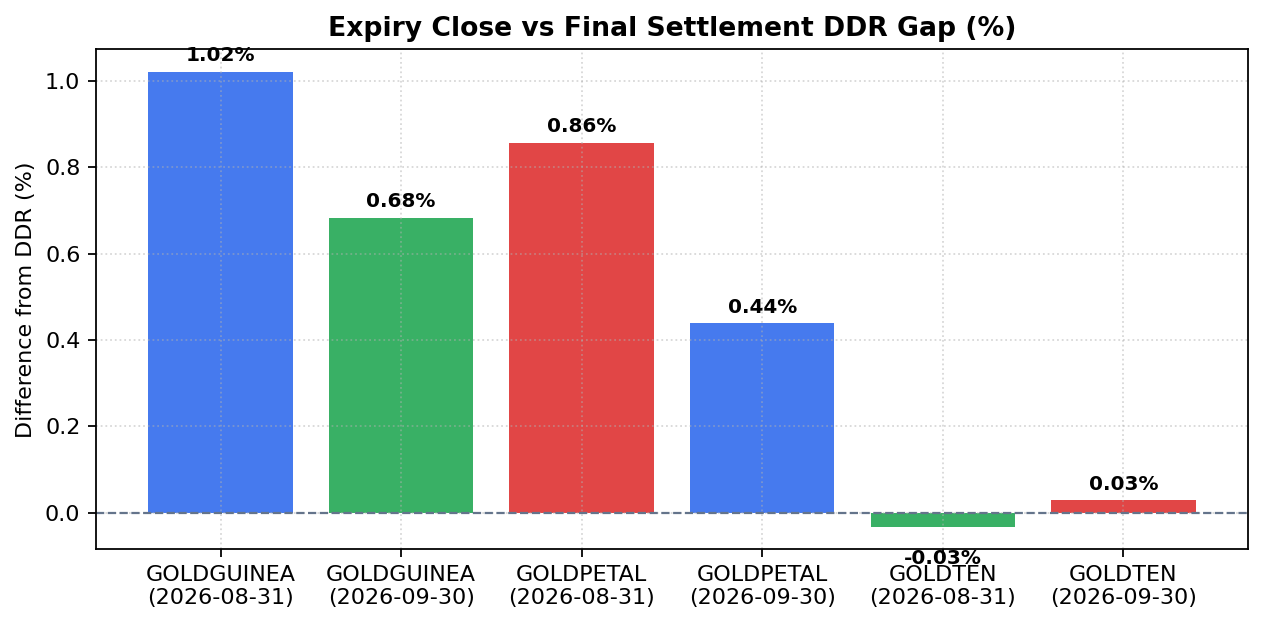

In [7]:
# Visualize convergence to Due Date Rate
fig, ax = plt.subplots(figsize=(8, 4), dpi=160)
bars = ax.bar(
    [f"{r['Symbol']}\n({r['Expiry']})" for _, r in df_conv.iterrows()],
    df_conv['Gap to DDR (%)'],
    color=['#2563EB', '#16A34A', '#DC2626', '#2563EB', '#16A34A', '#DC2626'],
    alpha=0.85
)
ax.axhline(0.0, color="#64748B", linestyle="--", linewidth=1)
ax.set_title("Expiry Close vs Final Settlement DDR Gap (%)", fontsize=12, fontweight="bold")
ax.set_ylabel("Difference from DDR (%)")
ax.grid(True, linestyle=":", alpha=0.5)
plt.show()


> ### 💡 Early Finding #2:
> **At final settlement (DDR), the trading premium disappears:**
> * **GOLDGUINEA** ends at about **0.00%** from DDR.
> * **GOLDPETAL** ends within **-0.01% to -0.26%**.
> DDR is the exchange cash settlement benchmark; retail trading markups collapse as physical delivery approaches.


---
## Chapter 6: Pairs Trading Backtest & Cost Breakdown (Empirical Finding #3)

Because GOLDPETAL trades at a premium to GOLDTEN during active trading and converges at expiry, a retail trader might attempt a pairs trade:
* **Buy GOLDTEN (10g)**
* **Sell GOLDPETAL (10 $\times$ 1g = 10g)** in equal physical weight.

### Institutional Friction Schedule:
Our backtest incorporates realistic statutory taxes and exchange levies:
1. **Brokerage**: Min (Rs 20 flat, 0.03%) per order
2. **Commodity Transaction Tax (CTT)**: 0.01% on sell leg value
3. **Exchange Transaction Charge**: 0.0021% on total turnover
4. **SEBI Turnover Fee**: Rs 10 per crore (0.0001%)
5. **Stamp Duty**: 0.002% on buy turnover
6. **GST**: 18% on fees
7. **Slippage**: 0.03% on each leg fill

Let's inspect the realized trade log from `results_bt/trades.csv`.


In [8]:
# Load realized backtest trades
df_trades = core.load_trades_data("results_bt/trades.csv")
display_cols = ['strategy', 'expiry', 'period', 'entry_date', 'exit_date', 'days_held', 'gross_pnl', 'fees', 'slippage', 'net_pnl_fees_slippage']
existing_cols = [c for c in display_cols if c in df_trades.columns]
print(f"Total realized pairs trades: {len(df_trades)}")
if 'gross_pnl' in df_trades.columns:
    print(f"Total Gross P&L: Rs {df_trades['gross_pnl'].sum():.2f}")
if 'fees' in df_trades.columns:
    print(f"Total Statutory & Brokerage Fees: Rs {df_trades['fees'].sum():.2f}")
if 'net_pnl_fees_slippage' in df_trades.columns:
    print(f"Total Net P&L (after fees + slippage): Rs {df_trades['net_pnl_fees_slippage'].sum():.2f}")

df_trades[existing_cols]


Total realized pairs trades: 5
Total Gross P&L: Rs 1556.00
Total Statutory & Brokerage Fees: Rs 730.73
Total Net P&L (after fees + slippage): Rs -77.49

     strategy     expiry                      period entry_date  exit_date  days_held  gross_pnl   fees  slippage  net_pnl_fees_slippage
HOLD_BASELINE 2026-08-31 descriptive, no test period 2026-08-03 2026-08-24         15      272.0 146.85    183.00                 -57.84
HOLD_BASELINE 2026-09-30 descriptive, no test period 2026-08-03 2026-09-23         37      603.0 145.29    177.52                 280.19
HOLD_BASELINE 2026-10-30 descriptive, no test period 2026-08-03 2026-10-01         43      669.0 145.13    176.97                 346.89
    REVERSION 2026-10-30               Design period 2026-08-31 2026-09-07          5      -12.0 147.77    186.26                -346.02
    REVERSION 2026-10-30          Unseen test period 2026-09-30 2026-10-01          1       24.0 145.69    179.01                -300.71


> ### 💡 Early Finding #3:
> **Gross results were mixed (some trades gained, some lost) and no reliable profit remained after assumed costs.**
> Transaction friction (CTT, GST, exchange charges, brokerage) and bid-ask slippage on small retail lots erode paper arbitrage spreads. Sample is small (3 expiries analyzed).


---
## Chapter 7: Production Engine: Zero-Lookahead Monitor & Signal Filters

In our production engine (`core.py` and `app.py`), the model enforces three institutional rules to avoid false alarms:
1. **Zero Look-ahead Bias**: The normal gap level is calculated using `gap_series.shift(1).rolling(10).mean()`. Today's price is strictly excluded.
2. **Break-even Threshold**: A signal is only flagged if $|\text{Gap} - \text{Normal Level}| > 0.22\%$ (assumed round-trip cost).
3. **Liquidity Cutoff**: No signals are generated within the last 10 calendar days to expiry ($DTE \le 10$) to avoid delivery margin penalties (MCX 8.34% tender margin in the last 3 days).

Let's inspect the contract lifecycle timeline and physical turnover volume.


In [9]:
# Compute contract lifecycle timeline and volume analysis
contracts_info, df_vol = core.compute_calendar_timeline(df_clean, df_trades)

print("Contract Volume Liquidity Turnover (Grams/Day):")
print(df_vol.to_string(index=False))


Contract Volume Liquidity Turnover (Grams/Day):
  Contract     Expiry  Lot Size (g)  Avg Daily Lots  Avg Daily Volume (g)  Avg Daily Volume (kg)  Trading Days Liquidity Flag
     GOLDM 2026-10-05           100    32846.727273          3.284673e+06            3284.672727            44         Normal
     GOLDM 2026-11-05           100     9852.568182          9.852568e+05             985.256818            44         Normal
   GOLDTEN 2026-09-30            10    23040.581395          2.304058e+05             230.405814            43         Normal
   GOLDTEN 2026-08-31            10    22190.809524          2.219081e+05             221.908095            21         Normal
 GOLDPETAL 2026-09-30             1   202707.232558          2.027072e+05             202.707233            43         Normal
 GOLDPETAL 2026-08-31             1   189112.666667          1.891127e+05             189.112667            21         Normal
   GOLDTEN 2026-10-30            10    11648.772727          1.164877e

---
## Chapter 8: Interactive Streamlit Dashboard

All calculations, rolling metrics, and real-time alerts demonstrated in this notebook are deployed inside the interactive Streamlit dashboard located in the `streamlit/` folder.

### How to Launch the Dashboard:
```bash
streamlit run streamlit/app.py
```
*(Or from the repository root: `streamlit run app.py`)*

### Key Dashboard Tabs:
1. **Today**: Live market status banner (Green "No signal today" or Amber "Signal") and active expiry reference comparison tables.
2. **Gap monitor**: Multi-contract gap time series against the GOLDM / GOLDTEN reference with normal level $\pm$ break-even bands.
3. **Settlement**: Due Date Rate (DDR) physical settlement convergence table and difference charts.
4. **Backtest**: Realized trade logs, gross vs net of fees and slippage returns, and performance equity curves.
5. **Calendar & liquidity**: Gantt chart of contract lifecycles, tender periods (3 days, 8.34% extra margin), no-new-entries limits, and daily turnover in physical grams.
6. **Method & limits**: Transparent MCX contract specifications table and complete list of analytical assumptions.
